In [1]:
# 1. Google Driveのマウント
from google.colab import drive
drive.mount('/content/drive')

# 2. ローカルSSD (/content) へのデータセット展開
!rm -rf /content/dataset_raw /content/so100_v3_dataset
!mkdir -p /content/dataset_raw
!tar -xzvf /content/drive/MyDrive/SO100_AI/so100_obstacle_dataset.tar.gz -C /content/dataset_raw/

# 3. LeRobotのクローンとデータセット拡張パッケージのインストール
%cd /content
!git clone https://github.com/huggingface/lerobot.git
%cd /content/lerobot
!pip install -e ".[dataset]"
!pip install av h5py

# 4. 【重要パッチ】未使用VLMポリシー (Qwen2.5-VL / WallOSS05) の巻き添えImportErrorを無力化
import glob
qwen_files = glob.glob("/usr/local/lib/python*/dist-packages/transformers/models/qwen2_5_vl/modeling_qwen2_5_vl.py")
for qf in qwen_files:
    with open(qf, "a") as f:
        f.write("\ndef apply_multimodal_rotary_pos_emb(*args, **kwargs): pass\n")

!mkdir -p /content/lerobot/src/lerobot/policies/wall_oss_05
!echo "class WallOSS05Policy: pass" > /content/lerobot/src/lerobot/policies/wall_oss_05/__init__.py
print("✅ 環境構築およびパッチ適用が完了しました！")


ストリーミング出力は最後の 5000 行に切り捨てられました。
processed/episode_083/images/frame_00059.jpg
processed/episode_083/images/frame_00016.jpg
processed/episode_083/images/frame_00036.jpg
processed/episode_083/images/frame_00077.jpg
processed/episode_083/images/frame_00011.jpg
processed/episode_083/images/frame_00111.jpg
processed/episode_083/images/frame_00004.jpg
processed/episode_083/images/frame_00173.jpg
processed/episode_083/images/frame_00093.jpg
processed/episode_083/images/frame_00018.jpg
processed/episode_083/images/frame_00029.jpg
processed/episode_083/images/frame_00112.jpg
processed/episode_083/images/frame_00001.jpg
processed/episode_083/images/frame_00075.jpg
processed/episode_083/images/frame_00120.jpg
processed/episode_083/images/frame_00038.jpg
processed/episode_083/images/frame_00144.jpg
processed/episode_083/images/frame_00026.jpg
processed/episode_083/images/frame_00168.jpg
processed/episode_083/images/frame_00067.jpg
processed/episode_083/images/frame_00082.jpg
processed/episode_083/i

In [2]:
import sys
sys.path.insert(0, "/content/lerobot/src")
import os, shutil, glob
import numpy as np
from PIL import Image as PILImage
from lerobot.datasets.lerobot_dataset import LeRobotDataset
from lerobot.configs.video import RGBEncoderConfig

root_dir = "/content/so100_v3_dataset"
shutil.rmtree(root_dir, ignore_errors=True)
encoder_cfg = RGBEncoderConfig(vcodec="h264")

joint_names = [
    "shoulder_pan", "shoulder_lift", "elbow_flex",
    "wrist_flex", "wrist_roll", "gripper_joint"
]

proc_episodes = sorted(glob.glob("/content/dataset_raw/processed/episode_*"))
print(f"📂 画像+NumPy (processed) 形式を検出しました（全 {len(proc_episodes)} エピソード）")
sample_state = np.load(f"{proc_episodes[0]}/states.npy")[0]
sample_img = np.array(PILImage.open(sorted(glob.glob(f"{proc_episodes[0]}/images/frame_*.jpg"))[0]).convert("RGB"))
state_dim = sample_state.shape[0]
img_shape = sample_img.shape

# 1. LeRobot 純正スキーマでデータセットを初期化
dataset = LeRobotDataset.create(
    repo_id="local/so100_obstacle",
    fps=30,
    root=root_dir,
    robot_type="so100",
    use_videos=False,
    rgb_encoder=encoder_cfg,
    features={
        "observation.images.camera": {
            "dtype": "image",
            "shape": img_shape,
            "names": ["height", "width", "channels"],
        },
        "observation.state": {
            "dtype": "float32",
            "shape": (state_dim,),
            "names": joint_names,
        },
        "action": {
            "dtype": "float32",
            "shape": (state_dim,),
            "names": joint_names,
        },
    },
)

# 2. 全エピソードのフレーム登録
for ep_idx, ep_path in enumerate(proc_episodes):
    states = np.load(f"{ep_path}/states.npy").astype(np.float32)
    actions = np.load(f"{ep_path}/actions.npy").astype(np.float32)
    img_paths = sorted(glob.glob(f"{ep_path}/images/frame_*.jpg"))
    num_frames = min(len(states), len(actions), len(img_paths))
    for i in range(num_frames):
        img = np.array(PILImage.open(img_paths[i]).convert("RGB"))
        dataset.add_frame({
            "observation.images.camera": img,
            "observation.state": states[i],
            "action": actions[i],
            "task": "Pick up the blue cube behind the red obstacle",
        })
    dataset.save_episode()
    if (ep_idx + 1) % 10 == 0 or (ep_idx + 1) == len(proc_episodes):
        print(f"Episode {ep_idx + 1}/{len(proc_episodes)} 変換完了 ({num_frames} frames)")

# 3. 全体の正規化データ (meta/stats.json) と Parquet メタデータを確定
if hasattr(dataset, "finalize"):
    dataset.finalize()

print("✅ 純正データセットおよび stats.json の生成が完了しました！")
!ls -la /content/so100_v3_dataset/meta/


📂 画像+NumPy (processed) 形式を検出しました（全 100 エピソード）


Map:   0%|          | 0/180 [00:00<?, ? examples/s]

Map:   0%|          | 0/180 [00:00<?, ? examples/s]

Map:   0%|          | 0/180 [00:00<?, ? examples/s]

Map:   0%|          | 0/180 [00:00<?, ? examples/s]

Map:   0%|          | 0/180 [00:00<?, ? examples/s]

... (101 outputs left out)

Map:   0%|          | 0/180 [00:00<?, ? examples/s]

Map:   0%|          | 0/180 [00:00<?, ? examples/s]

Map:   0%|          | 0/180 [00:00<?, ? examples/s]

Episode 100/100 変換完了 (180 frames)
✅ 純正データセットおよび stats.json の生成が完了しました！
total 32
drwxr-xr-x 3 root root  4096 Nov  2 23:52 .
drwxr-xr-x 5 root root  4096 Nov  2 23:51 ..
drwxr-xr-x 3 root root  4096 Nov  2 23:52 episodes
-rw-r--r-- 1 root root  2146 Nov  2 23:56 info.json
-rw-r--r-- 1 root root 10234 Nov  2 23:56 stats.json
-rw-r--r-- 1 root root  2213 Nov  2 23:51 tasks.parquet


In [3]:
%cd /content/lerobot
!rm -rf /content/lerobot/outputs/train/so100_act
!mkdir -p /content/lerobot/src/lerobot/policies/wall_oss_05
!echo "class WallOSS05Policy: pass" > /content/lerobot/src/lerobot/policies/wall_oss_05/__init__.py

!PYTHONPATH=/content/lerobot/src python -m lerobot.scripts.lerobot_train \
  --policy.type act \
  --policy.push_to_hub false \
  --policy.device cuda \
  --dataset.repo_id local/so100_obstacle \
  --dataset.root /content/so100_v3_dataset \
  --output_dir /content/lerobot/outputs/train/so100_act \
  --steps 4000 \
  --save_freq 1000 \
  --env_eval_freq -1 \
  --batch_size 8


/content/lerobot
INFO 2026-11-02 23:56:50 ot_train.py:565 {'accelerator': {'activation_checkpointing': {'mode': <ActivationCheckpointingMode.NONE: 'none'>},
                 'compile': {'backend': 'inductor',
                             'enabled': False,
                             'mode': None,
                             'regional': True},
                 'ddp': {'find_unused_parameters': True,
                         'gradient_as_bucket_view': False,
                         'static_graph': False},
                 'fsdp': {'cpu_offload': False,
                          'ignored_modules': None,
                          'min_num_params': None,
                          'mixed_precision_policy': {'cast_forward_inputs': True,
                                                     'output_dtype': None,
                                                     'param_dtype': None,
                                                     'reduce_dtype': None},
                          'resha

Loading weights from local directory


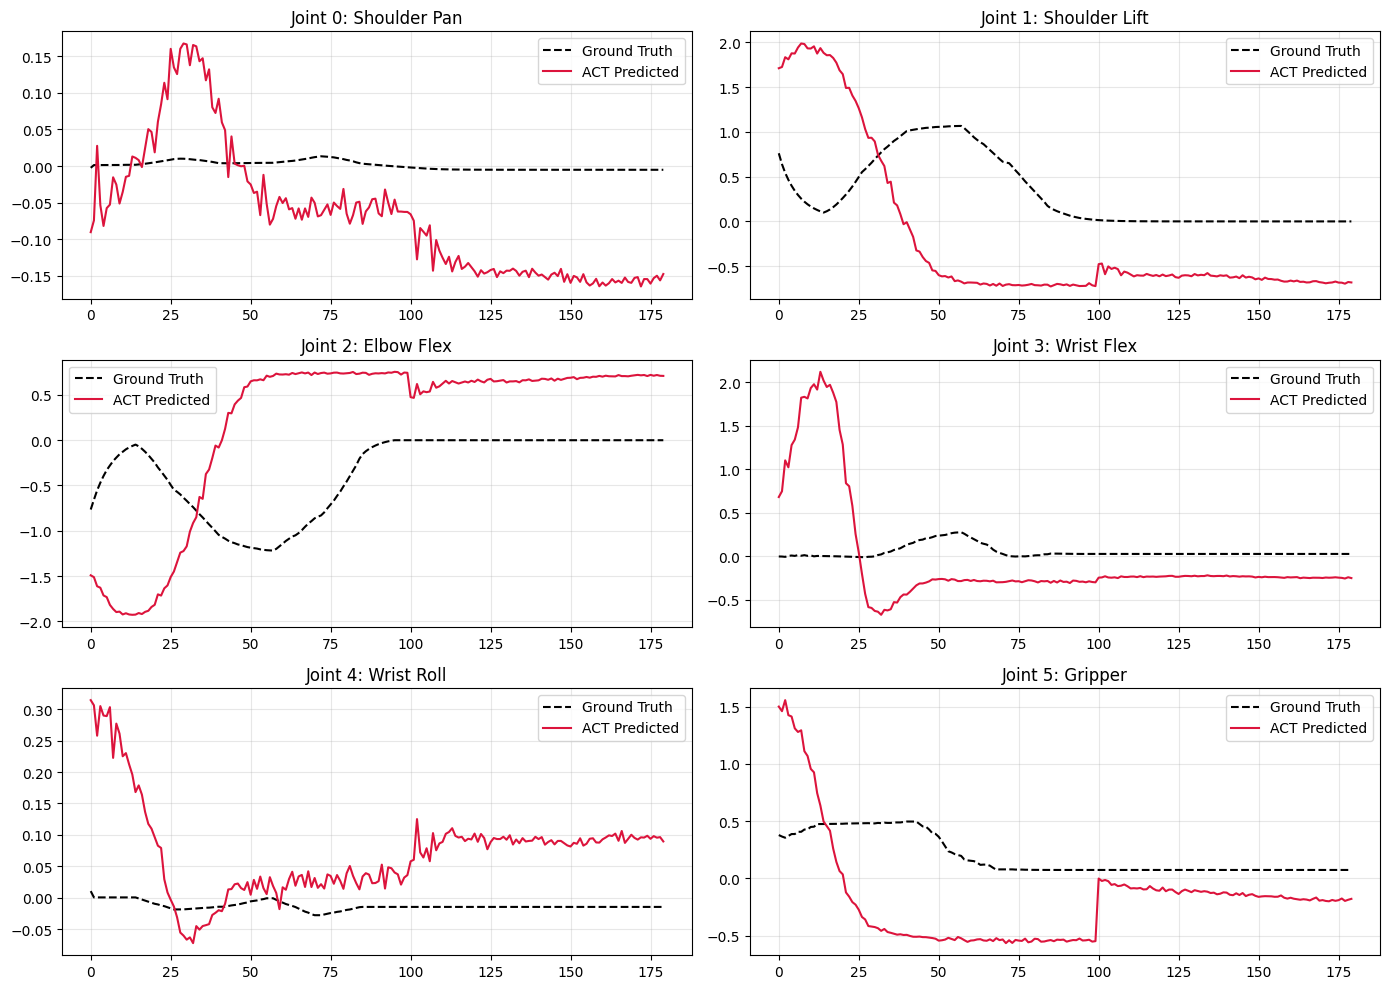

In [4]:
import sys, torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image as PILImage
import glob

sys.path.insert(0, "/content/lerobot/src")
from lerobot.policies.act.modeling_act import ACTPolicy

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_dir = Path("/content/lerobot/outputs/train/so100_act/checkpoints/004000/pretrained_model")

policy = ACTPolicy.from_pretrained(model_dir).to(device).eval()
policy.reset()

ep_dir = "/content/dataset_raw/processed/episode_001"
states = np.load(f"{ep_dir}/states.npy")
actions_gt = np.load(f"{ep_dir}/actions.npy")
img_paths = sorted(glob.glob(f"{ep_dir}/images/frame_*.jpg"))
n_frames = min(len(states), len(img_paths))

predicted_actions = []
with torch.no_grad():
    for t in range(n_frames):
        img = np.array(PILImage.open(img_paths[t]).convert("RGB"))
        img_tensor = torch.from_numpy(img).permute(2, 0, 1).unsqueeze(0).float() / 255.0
        state_tensor = torch.from_numpy(states[t]).unsqueeze(0).float()
        act = policy.select_action({
            "observation.images.camera": img_tensor.to(device),
            "observation.state": state_tensor.to(device),
        })
        predicted_actions.append(act.squeeze(0).cpu().numpy())

predicted_actions = np.array(predicted_actions)
joint_names = ["Shoulder Pan", "Shoulder Lift", "Elbow Flex", "Wrist Flex", "Wrist Roll", "Gripper"]
fig, axes = plt.subplots(3, 2, figsize=(14, 10))
axes = axes.flatten()

for i in range(6):
    axes[i].plot(actions_gt[:n_frames, i], label="Ground Truth", color="black", linestyle="--")
    axes[i].plot(predicted_actions[:, i], label="ACT Predicted", color="crimson")
    axes[i].set_title(f"Joint {i}: {joint_names[i]}")
    axes[i].grid(True, alpha=0.3)
    axes[i].legend()

plt.tight_layout()
plt.show()


In [5]:
import os, shutil

checkpoint_dir = "/content/lerobot/outputs/train/so100_act/checkpoints/004000/pretrained_model"
drive_dest = "/content/drive/MyDrive/SO100_AI/act_model_4000"

if os.path.exists(drive_dest):
    shutil.rmtree(drive_dest)
shutil.copytree(checkpoint_dir, drive_dest)

# 圧縮アーカイブとしても保存
export_dir = "/content/so100_act_export"
shutil.rmtree(export_dir, ignore_errors=True)
os.makedirs(export_dir, exist_ok=True)
shutil.copytree(checkpoint_dir, f"{export_dir}/pretrained_model")

archive_path = "/content/drive/MyDrive/SO100_AI/so100_act_trained_model"
shutil.make_archive(archive_path, 'gztar', root_dir=export_dir)
print(f"✅ バックアップ完了！7ファイル一式が保存されました:")
!ls -lh "{drive_dest}"


✅ バックアップ完了！7ファイル一式が保存されました:
total 198M
-rw------- 1 root root 1.6K Nov  3 00:05 config.json
-rw------- 1 root root 198M Nov  3 00:05 model.safetensors
-rw------- 1 root root  660 Nov  3 00:05 policy_postprocessor.json
-rw------- 1 root root 6.5K Nov  3 00:05 policy_postprocessor_step_0_unnormalizer_processor.safetensors
-rw------- 1 root root 1.2K Nov  3 00:05 policy_preprocessor.json
-rw------- 1 root root 6.5K Nov  3 00:05 policy_preprocessor_step_3_normalizer_processor.safetensors
-rw------- 1 root root 7.9K Nov  3 00:05 train_config.json
